<a href="https://colab.research.google.com/github/Ayman4786/ML-LAB/blob/main/ML_2_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Program 1

In [ ]:
def find_s_algorithm(examples, target):
    # Initialize most specific hypothesis
    hypothesis = ["φ"] * len(examples[0][0])

    # Consider only positive examples
    for attributes, label in examples:
        if label == target:
            for i in range(len(attributes)):
                if hypothesis[i] == "φ":
                    hypothesis[i] = attributes[i]
                elif hypothesis[i] != attributes[i]:
                    hypothesis[i] = "?"

    return hypothesis


# Dataset: (attributes, target)
dataset = [
    (["Sunny", "Hot", "High", "Weak"], "No"),
    (["Sunny", "Hot", "High", "Strong"], "No"),
    (["Overcast", "Hot", "High", "Weak"], "Yes"),
    (["Rainy", "Mild", "High", "Weak"], "Yes"),
    (["Rainy", "Cool", "Normal", "Weak"], "Yes"),
    (["Rainy", "Cool", "Normal", "Strong"], "No")
]

# Find-S
final_hypothesis = find_s_algorithm(dataset, "Yes")

print("Final Hypothesis (Find-S):", final_hypothesis)

Final Hypothesis (Find-S): ['?', '?', '?', 'Weak']


# Program 1.2

In [ ]:
def more_general(h1, h2):
    """Check if h1 is more general than h2."""
    return all(
        x == "?" or (x != "φ" and (x == y or y == "φ"))
        for x, y in zip(h1, h2)
    )


def candidate_elimination(examples):
    n = len(examples[0][0])

    # Initialize S and G
    S = ["φ"] * n
    G = [["?"] * n]

    for attributes, label in examples:

        if label == "Yes":
            # Generalize S minimally
            for i in range(n):
                if S[i] == "φ":
                    S[i] = attributes[i]
                elif S[i] != attributes[i]:
                    S[i] = "?"

            # Remove hypotheses from G that are not
            # more general than S
            G = [g for g in G if more_general(g, S)]

        else:
            # Negative example: specialize G
            new_G = []

            for g in G:
                for i in range(n):
                    if g[i] == "?":
                        values = set(
                            example[0][i]
                            for example in examples
                        )

                        for value in values:
                            if value != attributes[i]:
                                new_hypothesis = g.copy()
                                new_hypothesis[i] = value

                                if more_general(new_hypothesis, S):
                                    new_G.append(new_hypothesis)

            G = new_G

    return S, G


# Dataset: (attributes, target)
dataset = [
    (["Sunny", "Hot", "High", "Weak"], "No"),
    (["Sunny", "Hot", "High", "Strong"], "No"),
    (["Overcast", "Hot", "High", "Weak"], "Yes"),
    (["Rainy", "Mild", "High", "Weak"], "Yes"),
    (["Rainy", "Cool", "Normal", "Weak"], "Yes"),
    (["Rainy", "Cool", "Normal", "Strong"], "No")
]


# Apply Candidate Elimination
S, G = candidate_elimination(dataset)

print("Final Specific Boundary (S):", S)
print("Final General Boundary (G):", G)

Final Specific Boundary (S): ['?', '?', '?', 'Weak']
Final General Boundary (G): []


# Program 3

In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load dataset
wine = load_wine()
X, y = wine.data, wine.target

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

# Bagging
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=50,
    random_state=42
)

bagging.fit(X_train, y_train)
bag_pred = bagging.predict(X_test)

# Boosting
boosting = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    random_state=42
)

boosting.fit(X_train, y_train)
boost_pred = boosting.predict(X_test)

# Accuracy
print("Bagging Accuracy:", accuracy_score(y_test, bag_pred))
print("Boosting Accuracy:", accuracy_score(y_test, boost_pred))

Bagging Accuracy: 0.9814814814814815
Boosting Accuracy: 0.9814814814814815


# Program 4

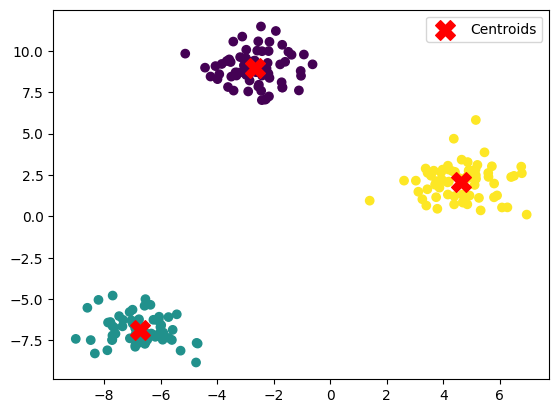

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Generate sample dataset
X, _ = make_blobs(
    n_samples=200,
    centers=3,
    random_state=42
)

# Apply K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

kmeans.fit(X)

labels = kmeans.labels_

# Plot clusters
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap="viridis"
)

# Plot centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.legend()
plt.show()

# Program 5

In [ ]:
pip install minisom

  Preparing metadata (setup.py) ... done
  Created wheel for minisom: filename=MiniSom-2.3.6-py3-none-any.whl size=13083 sha256=e175645709f48c07bff0029aac3ef1690bcd76463b1e7c77e01fc4fad766a974
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom


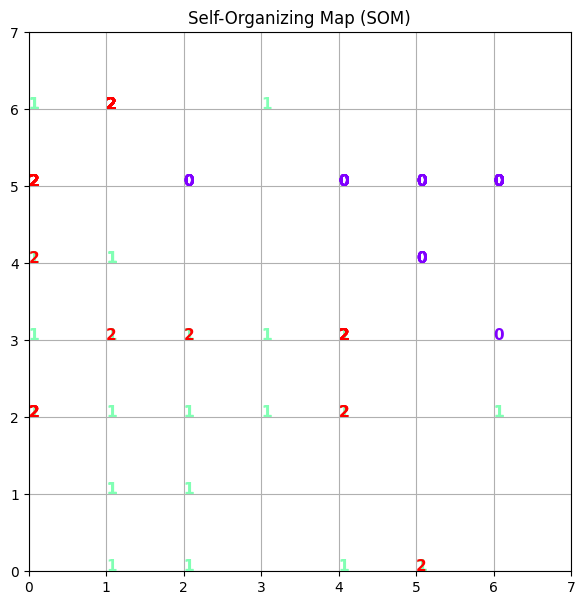

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

# Load Iris dataset
iris = load_iris()

# Normalize the data
X = MinMaxScaler().fit_transform(iris.data)

# Initialize SOM
som = MiniSom(
    x=7,
    y=7,
    input_len=4,
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# Initialize weights
som.random_weights_init(X)

# Train SOM
som.train_random(X, 100)

# Visualize SOM
plt.figure(figsize=(7, 7))

for i, x in enumerate(X):
    w = som.winner(x)

    plt.text(
        w[0],
        w[1],
        str(iris.target[i]),
        color=plt.cm.rainbow(iris.target[i] / 2),
        fontdict={"weight": "bold", "size": 11}
    )

plt.xlim(0, 7)
plt.ylim(0, 7)
plt.grid()
plt.title("Self-Organizing Map (SOM)")
plt.show()

# Program 6

In [ ]:
import numpy as np

# Function to integrate
def f(x):
    return x**2

# Generate random samples
N = 10000
samples = np.random.rand(N)

# Evaluate function
values = f(samples)

# Monte Carlo estimate
estimate = np.mean(values)

print("Estimated Integral of x^2 from 0 to 1:", estimate)

Estimated Integral of x^2 from 0 to 1: 0.33599955315179014


# Program 7

In [ ]:
pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 4.1 MB/s eta 0:00:00


In [ ]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# Create Bayesian Network
model = DiscreteBayesianNetwork([
    ("Rain", "Traffic"),
    ("Accident", "Traffic")
])

# Prior probability of Rain
cpd_rain = TabularCPD(
    variable="Rain",
    variable_card=2,
    values=[[0.7], [0.3]]
)

# Prior probability of Accident
cpd_accident = TabularCPD(
    variable="Accident",
    variable_card=2,
    values=[[0.9], [0.1]]
)

# Conditional Probability Table for Traffic
cpd_traffic = TabularCPD(
    variable="Traffic",
    variable_card=2,
    values=[
        [0.90, 0.60, 0.70, 0.20],
        [0.10, 0.40, 0.30, 0.80]
    ],
    evidence=["Rain", "Accident"],
    evidence_card=[2, 2]
)

# Add CPDs to the model
model.add_cpds(
    cpd_rain,
    cpd_accident,
    cpd_traffic
)

# Check model
print("Model valid:", model.check_model())

# Perform inference
infer = VariableElimination(model)

# Calculate likelihood of Traffic given Rain
result = infer.query(
    variables=["Traffic"],
    evidence={"Rain": 1}
)

print("\nP(Traffic | Rain=1):")
print(result)

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Model valid: True

P(Traffic | Rain=1):
+------------+----------------+
| Traffic    |   phi(Traffic) |
+============+================+
| Traffic(0) |         0.6500 |
+------------+----------------+
| Traffic(1) |         0.3500 |
+------------+----------------+


# Program 8

In [ ]:
from pgmpy.inference import VariableElimination

# Use the Bayesian Network created in Experiment 7
infer = VariableElimination(model)

# Inference with first evidence
result1 = infer.query(
    variables=["Traffic"],
    evidence={"Rain": 1}
)

print(
    "P(Traffic=1 | Rain=1):",
    result1.values
)

# Inference with additional evidence
result2 = infer.query(
    variables=["Traffic"],
    evidence={
        "Rain": 1,
        "Accident": 1
    }
)

print(
    "P(Traffic=1 | Rain=1, Accident=1):",
    result2.values
)

P(Traffic=1 | Rain=1): [0.65 0.35]
P(Traffic=1 | Rain=1, Accident=1): [0.2 0.8]
